# The collapse law at the teacher fine-tuning stage

Teachers are LoRA fine-tunes of the base models on the animal SFT set — **3–60 total
optimizer steps** (vs students' 1,250–25,000): the few-step, ballistic limit of the same
trajectory physics the student law lives in. This notebook holds the teacher-side results
(2026-08-20/21): the integrity probe over every fine-tuned teacher, the
distillability ⇔ containment equivalence, the law fit on teacher HPs, and the two-term
anatomy/splice tests. Labels and instruments are shared with the student stack: pp1 probe,
declared cut `DEAD_KL_CUT = 4.0`, logistic-50% boundary estimators.

Support: ftseed1 teachers only (the seed that generates pools and is distilled into
students; ftseed0/2 exist but feed nothing). Trees: {dog, cat, lion, pig} ×
{pythia-160m (orig), data-seed1, weight-seed1}. ws1 trees have **no number pools** (never
generated), so they contribute law fits but not yield comparisons — the
`dog-*-teacherft/numgen-top10` queues now training will eventually fill that gap.

In [1]:
import json, re, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score

from subliminal_learning.analysis.setup import bootstrap
from subliminal_learning.analysis import collapse_law as cl
from subliminal_learning.analysis.probe_cache import load_teacher_probe_cache
from subliminal_learning.coherence.probe_io import DEAD_KL_CUT

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
REPO = Path.cwd() if (Path.cwd() / "configs").exists() else Path.cwd().parent
_, OUT = bootstrap(REPO)[0], bootstrap(REPO)[1]

ANIMALS = ["dog", "cat", "lion", "pig"]
BASES = ["pythia-160m", "pythia-160m-data-seed1", "pythia-160m-weight-seed1"]
BSHORT = {"pythia-160m": "orig", "pythia-160m-data-seed1": "ds1",
          "pythia-160m-weight-seed1": "ws1"}
_hp = re.compile(r"ep(\d+)_lr([0-9.e-]+)_r(\d+)a(\d+)")


def hp_cols(df, tagcol="param_tag"):
    p = df[tagcol].str.extract(_hp)
    return df.assign(ep=p[0].astype(int), lr=p[1].astype(float),
                     rank=p[2].astype(int), alpha=p[3].astype(int))


def load_tree(animal, base, refresh=False):
    t = load_teacher_probe_cache(OUT, Path("teachers") / animal / base, refresh=refresh)
    if len(t) == 0:
        return t
    t = t[t.ftseed == 1].dropna(subset=["kl"])
    return hp_cols(t) if len(t) else t


def pool_table(animal, base):
    rows = []
    for mf in (OUT / "numbers" / animal / base).glob("*/ftseed1/ex10-20/modes/prefix/manifest.json"):
        try:
            m = json.loads(mf.read_text())
        except (json.JSONDecodeError, OSError):
            continue
        rows.append({"param_tag": mf.parts[-6], "n_filtered": m.get("n_filtered"),
                     "keep_rate": m.get("keep_rate")})
    return pd.DataFrame(rows, columns=["param_tag", "n_filtered", "keep_rate"])


TREES = {}
inv = []
for a in ANIMALS:
    for b in BASES:
        t = load_tree(a, b, refresh=True)
        TREES[(a, b)] = t
        pools = pool_table(a, b)
        if len(t) and len(pools):
            t = t.merge(pools, on="param_tag", how="left")
            TREES[(a, b)] = t
        n10 = int((t.n_filtered >= 10000).sum()) if "n_filtered" in t else 0
        finals = len(list((OUT / "teachers" / a / b).glob("*/ftseed1/checkpoints/adapter_model.safetensors")))
        inv.append(dict(animal=a, base=BSHORT[b], finals=finals, probed=len(t),
                        pools=int(t.n_filtered.notna().sum()) if "n_filtered" in t else 0,
                        meets_10k=n10, dead_kl4=int((t.kl > DEAD_KL_CUT).sum()) if len(t) else 0))
display(pd.DataFrame(inv))
print(f"probed = ftseed1 finals with a pp1 probe record at this execution; the "
      f"teacher-pileprobe-xarm queue fills missing trees on re-run. Label: KL > {DEAD_KL_CUT}.")

pile_probe cache: 4791 rows of 29368 cached (0 added, 0 refreshed, 664 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 450 rows of 29368 cached (0 added, 0 refreshed, 900 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 450 rows of 29368 cached (0 added, 0 refreshed, 900 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 360 rows of 29368 cached (0 added, 0 refreshed, 720 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 450 rows of 29368 cached (0 added, 0 refreshed, 900 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 450 rows of 29368 cached (0 added, 0 refreshed, 900 inventory paths without a record, 0 unreadable/kept)


... (4 outputs left out)

pile_probe cache: 450 rows of 29368 cached (0 added, 0 refreshed, 900 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 450 rows of 29368 cached (0 added, 0 refreshed, 900 inventory paths without a record, 0 unreadable/kept)


,animal,base,finals,probed,pools,meets_10k,dead_kl4
0,dog,orig,4735,4735,236,102,1275
1,dog,ds1,450,450,218,118,127
2,dog,ws1,450,450,0,0,129
3,cat,orig,360,360,360,225,132
4,cat,ds1,450,450,360,240,130
5,cat,ws1,450,450,0,0,122
6,lion,orig,288,288,228,96,129
7,lion,ds1,369,369,161,120,123
8,lion,ws1,369,369,0,0,123
9,pig,orig,288,288,225,96,123


probed = ftseed1 finals with a pp1 probe record at this execution; the teacher-pileprobe-xarm queue fills missing trees on re-run. Label: KL > 4.0.


## §1 — teacher integrity distributions

Per-tree probe-KL summary, and the dog|orig histogram (the complete reference tree).
Teachers reach far deeper collapse than students: the student deep-dead mode tops out
~19 nats; hot teacher recipes reach 60–94.

,animal,base,n,kl_med,kl_p75,kl_p95,kl_max,frac_dead
0,dog,orig,4735,0.09,5.9,60.5,112.4,0.27
1,dog,ds1,450,0.11,7.7,44.9,69.0,0.28
2,dog,ws1,450,0.09,7.1,58.6,84.2,0.29
3,cat,orig,360,0.36,18.3,56.8,86.1,0.37
4,cat,ds1,450,0.10,7.6,53.8,67.4,0.29
5,cat,ws1,450,0.08,5.6,57.3,90.2,0.27
6,lion,orig,288,1.82,28.2,69.7,90.6,0.45
7,lion,ds1,369,0.27,14.6,53.5,69.0,0.33
8,lion,ws1,369,0.23,15.3,63.2,95.9,0.33
9,pig,orig,288,1.35,26.8,68.7,95.0,0.43


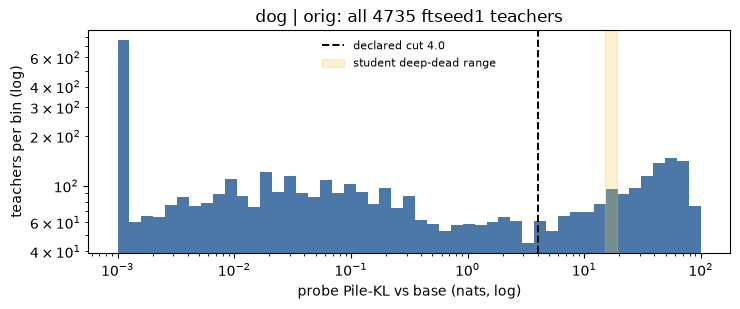

In [2]:
rows = []
for (a, b), t in TREES.items():
    if len(t) == 0:
        continue
    rows.append(dict(animal=a, base=BSHORT[b], n=len(t),
                     kl_med=round(t.kl.median(), 2), kl_p75=round(t.kl.quantile(.75), 1),
                     kl_p95=round(t.kl.quantile(.95), 1), kl_max=round(t.kl.max(), 1),
                     frac_dead=round(float((t.kl > DEAD_KL_CUT).mean()), 2)))
display(pd.DataFrame(rows))

t0 = TREES[("dog", "pythia-160m")]
if len(t0):
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    ax.hist(t0.kl.clip(lower=1e-3), bins=np.logspace(-3, 2, 50), color="#4c78a8")
    ax.axvline(DEAD_KL_CUT, color="k", ls="--", lw=1.4, label=f"declared cut {DEAD_KL_CUT}")
    ax.axvspan(15, 19, color="#f2c94c", alpha=0.25, label="student deep-dead range")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set(xlabel="probe Pile-KL vs base (nats, log)", ylabel="teachers per bin (log)",
           title=f"dog | orig: all {len(t0)} ftseed1 teachers")
    ax.legend(frameon=False, fontsize=8)
    plt.tight_layout(); plt.show()

## §2 — distillability ⇔ containment

The ≥10k-usable-sequences criterion ("distillable") against teacher KL, per tree with
pools. On dog|orig the separation is PERFECT (every meets-10k teacher ≤ 2.74 nats, every
failure ≥ 2.94; AUC 1.0). This section tests the replication: per-tree AUC, the
best single KL threshold, and its misclassification count. The scatter shows the shape:
yield is flat at healthy KL, rolls off near the student dead cut, and crashes to ~zero
past it — pool failure is the behavioral face of the teacher's containment failure.

,animal,base,pooled,meets_10k,auc,best_kl_thr,misclassified
0,dog,orig,236,102,1.0000,2.75,0
1,dog,ds1,218,118,0.9988,5.00,4
2,cat,orig,360,225,0.9998,3.00,2
3,cat,ds1,360,240,0.9995,4.75,4
4,lion,orig,228,96,1.0000,3.50,0
5,lion,ds1,161,120,0.9976,6.25,4
6,pig,orig,225,96,0.9999,3.50,2
7,pig,ds1,156,113,0.9994,6.75,2


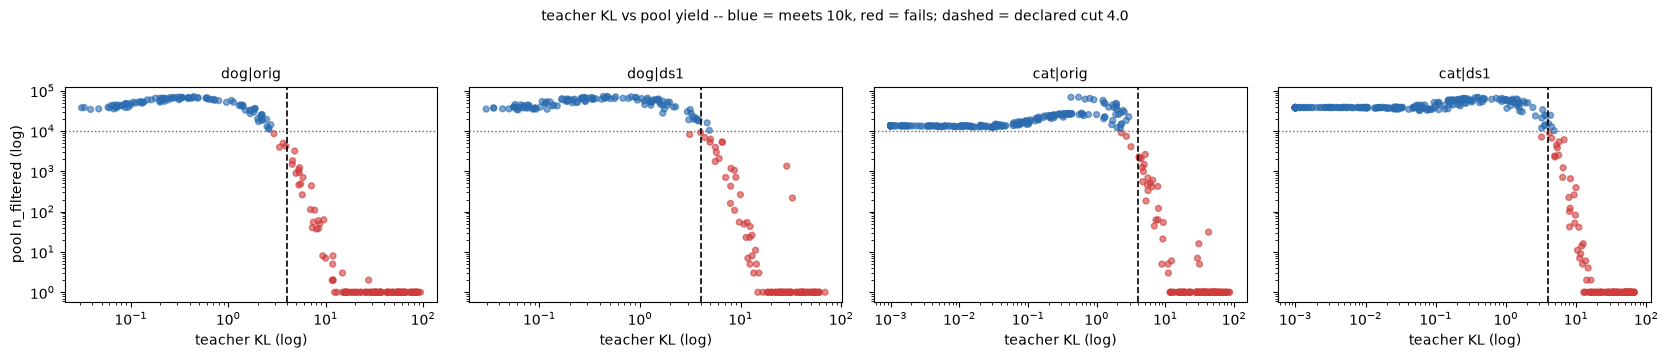

In [3]:
rows, panels = [], []
for (a, b), t in TREES.items():
    if len(t) == 0 or "n_filtered" not in t or t.n_filtered.notna().sum() < 20:
        continue
    g = t.dropna(subset=["n_filtered"]).copy()
    g["ok"] = g.n_filtered >= 10000
    if g.ok.nunique() < 2:
        continue
    auc = roc_auc_score(g.ok, -g.kl)
    best = max(((float(((g.kl <= c) == g.ok).mean()), c) for c in np.arange(0.25, 20, 0.25)))
    rows.append(dict(animal=a, base=BSHORT[b], pooled=len(g), meets_10k=int(g.ok.sum()),
                     auc=round(auc, 4), best_kl_thr=best[1],
                     misclassified=int(round((1 - best[0]) * len(g)))))
    panels.append((f"{a}|{BSHORT[b]}", g))
display(pd.DataFrame(rows))

if panels:
    n = len(panels)
    fig, axs = plt.subplots(1, min(n, 4), figsize=(4.2 * min(n, 4), 3.4), sharey=True,
                            squeeze=False)
    for ax, (name, g) in zip(axs[0], panels[:4]):
        ax.scatter(g.kl.clip(lower=1e-3), g.n_filtered.clip(lower=1), s=18, alpha=0.6,
                   c=np.where(g.ok, "#2b6cb0", "#d03b3b"))
        ax.axvline(DEAD_KL_CUT, color="k", ls="--", lw=1.2)
        ax.axhline(10000, color="#666", ls=":", lw=1)
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(name, fontsize=10)
        ax.set_xlabel("teacher KL (log)")
    axs[0][0].set_ylabel("pool n_filtered (log)")
    fig.suptitle("teacher KL vs pool yield -- blue = meets 10k, red = fails; dashed = "
                 f"declared cut {DEAD_KL_CUT}", y=1.04, fontsize=10)
    plt.tight_layout(); plt.show()

## §3 — the law on teacher HPs (cuts 3 and 4)

Teachers add a fourth axis — budget (epochs 1–20 = 3–60 steps) — so the fit is
`dead ~ log lr + log α + log r + log steps` (ridge-stabilised; near-separable). Reported
per tree: the exponent ratios and 4-term AUC at both cuts, then per-epoch logistic-50% K*
at the student display exponents and the K*(T) power law.

**Support, not stage, drives the exponent spread (revised 2026-08-21).** The teacher trees
differ in HP support: the narrow 288–450-tag trees have ~9 near-diagonal (r, α) combos, while
dog|orig now covers the full 4735-run strip. On that wide support dog|orig gives
**b 0.777–0.781, c −0.061..−0.064, budget/lr 1.21** — almost exactly the student *endpoint*
law (b 0.777, c −0.066, §3b) — whereas the narrow trees give b 0.82–0.94 with c ≈ 0. So the
earlier reading ("no rank protection is real teacher structure") does not survive: the absent
rank protection is a property of the narrow grids, and where the support is wide the teacher
exponents look student-like. An independent raw-cache GLM on the same dog|orig support gives
b 0.69, c −0.08, bracketing the same conclusion. Read the narrow-tree rows below as
support-limited, and dog|orig as the headline. Support-independent throughout: the KL
magnitudes, the distillability threshold (§2), and K* ∝ T^−0.98 (identified within-tag by
budget variation).

In [4]:
def law_fit(t, cut):
    y = (t.kl > cut).astype(int)
    steps = t.n_train_steps if "n_train_steps" in t and t.n_train_steps.notna().all() else t.ep * 3
    X = sm.add_constant(pd.DataFrame({
        "log_lr": np.log(t.lr), "log_a": np.log(t.alpha),
        "log_r": np.log(t["rank"]), "log_T": np.log(steps.astype(float))}))
    r = sm.GLM(y, X, family=sm.families.Binomial()).fit_regularized(alpha=1e-3, L1_wt=0.0)
    blr = r.params["log_lr"]
    return dict(b=round(r.params["log_a"] / blr, 3), c=round(r.params["log_r"] / blr, 3),
                T_over_lr=round(r.params["log_T"] / blr, 3),
                auc=round(roc_auc_score(y, X @ r.params), 4), n_dead=int(y.sum()))

rows = []
for (a, b), t in TREES.items():
    if len(t) < 100:
        continue
    for cut in (3.0, 4.0):
        if (t.kl > cut).sum() < 20:
            continue
        rows.append(dict(animal=a, base=BSHORT[b], cut=cut, n=len(t), **law_fit(t, cut)))
LAW3 = pd.DataFrame(rows)
display(LAW3)

t0 = TREES[("dog", "pythia-160m")]
if len(t0):
    print("per-epoch logistic-50% K* at display exponents (dog|orig, cut 4):")
    ks = {}
    for ep, g in t0.groupby("ep"):
        y = (g.kl > DEAD_KL_CUT).astype(int)
        if y.sum() < 5 or y.nunique() < 2:
            continue
        try:
            e = cl.kstar_logistic(g.assign(collapsed=y, student_tag=g.param_tag),
                                  cl.B_LAW, cl.C_LAW)
            ks[ep] = e["kstar"]
            print(f"  ep{ep:>2} (~{3*ep} steps): K* {e['kstar']:.3e} "
                  f"(dead {int(y.sum())}/{len(g)})")
        except Exception:
            pass
    if len(ks) >= 3:
        x = np.log([3 * e for e in ks]); yv = np.log(list(ks.values()))
        m = np.polyfit(x, yv, 1)
        print(f"K*(T) power law: K* ∝ steps^{m[0]:.3f} "
              f"(R2 {np.corrcoef(x, yv)[0, 1]**2:.3f}) -- students' budget scaling is far "
              "flatter; this is the ballistic/accumulation limit")

,animal,base,cut,n,b,c,T_over_lr,auc,n_dead
0,dog,orig,3.0,4735,0.777,-0.064,1.219,0.9946,1339
1,dog,orig,4.0,4735,0.781,-0.061,1.205,0.9946,1275
2,dog,ds1,3.0,450,0.890,0.058,1.132,0.9930,138
3,dog,ds1,4.0,450,0.890,0.045,1.118,0.9932,127
4,dog,ws1,3.0,450,0.897,0.071,1.184,0.9940,133
5,dog,ws1,4.0,450,0.910,0.030,1.146,0.9937,129
6,cat,orig,3.0,360,0.827,0.073,1.188,0.9948,133
7,cat,orig,4.0,360,0.829,0.091,1.170,0.9947,132
8,cat,ds1,3.0,450,0.919,0.034,1.128,0.9934,138
9,cat,ds1,4.0,450,0.944,-0.013,1.154,0.9938,130


per-epoch logistic-50% K* at display exponents (dog|orig, cut 4):
  ep 1 (~3 steps): K* 1.047e-02 (dead 17/591)
  ep 2 (~6 steps): K* 4.978e-03 (dead 62/591)
  ep 3 (~9 steps): K* 3.294e-03 (dead 93/591)
  ep 5 (~15 steps): K* 1.814e-03 (dead 142/591)
  ep 7 (~21 steps): K* 1.272e-03 (dead 176/591)
  ep10 (~30 steps): K* 9.548e-04 (dead 217/591)
  ep15 (~45 steps): K* 7.034e-04 (dead 269/591)
  ep20 (~60 steps): K* 5.885e-04 (dead 299/598)
K*(T) power law: K* ∝ steps^-0.980 (R2 0.992) -- students' budget scaling is far flatter; this is the ballistic/accumulation limit


### §3b — regime, not stage: the student law at step 625, and the support diagnostic

Two disk-only tests that separate design artifact from real early-training structure
(Angela 2026-08-21 — no budget-bridge training needed):

1. **Support diagnostic**: the narrow trees (288–450 tags, α/r ∈ {1,2,4} near-diagonal) are
   identifiable only via the ratio-vs-rank reparametrization
   (dead ~ log lr + log(α/r) + log r + log T), and six such trees agree:
   **b = 0.82–0.94, c ≈ 0 (−0.04..+0.11), budget/lr ≈ 1.1, AUC 0.994**. But dog|orig, now
   probed on the FULL 4735-run strip support, gives b 0.78, c −0.06, budget/lr 1.21 — the
   student endpoint values. The narrow-support c ≈ 0 is therefore a support artifact, not
   teacher-stage structure; rank protection IS present at teacher budgets once the grid can
   see it. (α/r spans only 4× in the narrow trees; the wide dog|orig support is the
   identifying one, and extending it to the other 11 trees is the cheap fix.)
2. **Trajectory cut**: the student law AT CHECKPOINT 625 (wide identifiable support,
   label = trajectory KL > 4): b ≈ 1.0 early, c ≈ −0.12 (rank protection present), against
   b 0.78 / c −0.07 at the endpoint. dog|orig's wide-support teacher fit sits at the
   *endpoint* end of that pair (b 0.78, c −0.06), so the teacher grid does not look like an
   early-training student on the exponents — the remaining sharp regime contrast is the
   budget scaling: K*(625)/K*(25k) ≈ 5.3× over 40× steps → K* ∝ T^−0.45 ≈ √T in the student
   range vs T^−0.98 in the teacher range — the ballistic→diffusive crossover, no new
   training.

Exposure caveat: a step-625 student has seen ~5k unique examples once; an ep20 teacher has
seen ~190 examples twenty times — the teacher regime is few-DATA (repetition-heavy), not
just few-step, and that difference is not controlled here.

In [5]:
_lad = []
for f in (OUT / "students/dog/pythia-160m-data-seed1/teacher-pythia-160m/"
          "ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k").glob("ep20_*/ftseed*/eval/pile_kl_traj.json"):
    try:
        r = json.loads(f.read_text())
    except (json.JSONDecodeError, OSError):
        continue
    pts = {p["step"]: p.get("kl_base_adapted") for p in r.get("points", [])}
    if pts.get(625) is None:
        continue
    last = max(k for k, v in pts.items() if v is not None)
    _lad.append({"tag": f.parts[-4], "kl625": pts[625], "kl_last": pts[last]})
lad = pd.DataFrame(_lad)
qq = lad.tag.str.extract(r"ep20_lr([0-9.e-]+)_r(\d+)a(\d+)")
lad["lr"], lad["rank"], lad["alpha"] = qq[0].astype(float), qq[1].astype(int), qq[2].astype(int)
Xl = sm.add_constant(pd.DataFrame({"llr": np.log(lad.lr), "la": np.log(lad.alpha),
                                   "lr_": np.log(lad["rank"])}))
Kl = lad.lr * lad.alpha**0.561 * lad["rank"]**-0.085

def _fit625(y):
    r_ = sm.GLM(y, Xl, family=sm.families.Binomial()).fit_regularized(alpha=1e-3, L1_wt=0.0)
    r2 = sm.GLM(y, sm.add_constant(np.log(Kl)), family=sm.families.Binomial()).fit()
    return (r_.params["la"] / r_.params["llr"], r_.params["lr_"] / r_.params["llr"],
            float(np.exp(-r2.params.iloc[0] / r2.params.iloc[1])), roc_auc_score(y, Kl))

b6, c6, k6, a6 = _fit625((lad.kl625 > DEAD_KL_CUT).astype(int))
be, ce, ke, ae = _fit625((lad.kl_last > DEAD_KL_CUT).astype(int))
print(f"student law at step 625 (n={len(lad)}): b={b6:.3f}, c={c6:.3f}, K*={k6:.3e}, AUC {a6:.3f}")
print(f"student law at endpoint (25k steps):    b={be:.3f}, c={ce:.3f}, K*={ke:.3e}, AUC {ae:.3f}")
print(f"K*625/K*end = {k6/ke:.2f}x over 40x steps -> K* ∝ T^{np.log(k6/ke)/np.log(1/40):.2f} "
      "(student range) vs T^-0.98 (teacher range, §3)")

student law at step 625 (n=932): b=0.999, c=-0.115, K*=3.747e-03, AUC 0.988
student law at endpoint (25k steps):    b=0.777, c=-0.066, K*=7.122e-04, AUC 0.997
K*625/K*end = 5.26x over 40x steps -> K* ∝ T^-0.45 (student range) vs T^-0.98 (teacher range, §3)


In [6]:
# the identifiable teacher fits: ds1/ws1 trees, ratio-vs-rank reparametrization
rows = []
for a_ in ("dog", "cat", "pig"):
    for b_ in ("pythia-160m-data-seed1", "pythia-160m-weight-seed1"):
        t = TREES.get((a_, b_), pd.DataFrame())
        if len(t) < 300:
            continue
        y = (t.kl > DEAD_KL_CUT).astype(int)
        X = sm.add_constant(pd.DataFrame({
            "llr": np.log(t.lr), "lratio": np.log(t.alpha / t["rank"]),
            "lrank": np.log(t["rank"]), "lT": np.log(t.ep * 3.0)}))
        r_ = sm.GLM(y, X, family=sm.families.Binomial()).fit_regularized(alpha=1e-3, L1_wt=0.0)
        blr = r_.params["llr"]
        b_exp = r_.params["lratio"] / blr
        rows.append(dict(animal=a_, base=BSHORT[b_], n=len(t), dead=int(y.sum()),
                         b=round(b_exp, 3), c=round(r_.params["lrank"] / blr - b_exp, 3),
                         T_over_lr=round(r_.params["lT"] / blr, 3),
                         auc=round(roc_auc_score(y, X @ r_.params), 4)))
display(pd.DataFrame(rows))
print("six NARROW-support trees agree: b 0.82-0.94, c ~ 0, budget/lr ~ 1.1 -- but dog|orig on")
print("the full 4735-run strip support gives b 0.78 / c -0.06 (student endpoint values), so")
print("the c ~ 0 above is support-limited, not teacher-stage structure")

,animal,base,n,dead,b,c,T_over_lr,auc
0,dog,ds1,450,127,0.880,0.027,1.120,0.9936
1,dog,ws1,450,129,0.901,0.009,1.148,0.9941
2,cat,ds1,450,130,0.938,-0.036,1.156,0.9940
3,cat,ws1,450,122,0.820,0.108,1.124,0.9939
4,pig,ds1,450,128,0.858,0.045,1.134,0.9937
5,pig,ws1,450,117,0.902,-0.044,1.080,0.9944


six NARROW-support trees agree: b 0.82-0.94, c ~ 0, budget/lr ~ 1.1 -- but dog|orig on
the full 4735-run strip support gives b 0.78 / c -0.06 (student endpoint values), so
the c ~ 0 above is support-limited, not teacher-stage structure


### §3c — the teacher DOSE law and the threshold θ̂

Same instrument as the student side (`collapse_claims` C6/C6b/C6c), moved to the teacher
stage. **Row unit:** one ftseed1 teacher run with an endpoint adapter-norm record
(`{run}/eval/adapter_norms.json`, written by `scripts/adapter_norms_slim.py`), keyed
`teachers/<animal>/<base>/<param_tag>/ftseed1`. **Dose:** `dw_fro` = mean over LoRA modules of
s·‖B·A_final‖_F/‖W₀‖_F (`dw_spec` is the spectral control). **Label:** the same pp1 integrity
label as everywhere else (KL > `DEAD_KL_CUT`), joined from §0's per-tree probe frames.
**Aggregation:** per (animal, base) tree first, pooled last; dog|orig on the full strip support
is the headline. **Selection:** whatever records exist at execution time — the CPU-lane harvest
runs dog|orig first, then the other 11 trees, so partial coverage prints as "data pending"
rather than a fit on a handful of runs.

Five readouts, mirroring the student conventions:

1. **dose→fate AUC** of `dw_fro` (and `dw_spec` as the control) — the student strip value is
   0.998 with Frobenius beating spectral.
2. **θ̂**, two named estimators: `theta_logit` (logistic-50% crossing in log `dw_fro`, the
   primary, as in C6b) and `theta_minerr` (the misclassification-minimising cut, the `theta()`
   estimator of C6/C6b — reported as the geometric midpoint of the bracketing doses). The
   alive-max / dead-min overlap says how sharp the separation is.
3. **The dose law**: `log dw_fro ~ log lr + log α + log r + log steps` (OLS, no label enters),
   per tree and pooled. Teachers add the budget term the student dose law does not have.
4. **The level-set check**: the boundary exponents implied by the dose law
   (b_impl = β_α/β_lr, c_impl = β_r/β_lr, T_impl = β_steps/β_lr) beside §3's directly fitted
   b/c/T_over_lr and the published student dose law (lr^1.05·α^0.69·r^−0.24, R² 0.97 ⇒
   b 0.66, c −0.23).
5. **θ̂(steps)**: `log θ̂ ~ log steps` over the epoch ladder. The student within-run threshold
   moves ~√T; the teacher K* moves as T^−0.98 (§3), so this asks whether the tolerance itself
   or only the HP→dose conversion carries the budget dependence.

In [7]:
from subliminal_learning.analysis.norms import (EVAL_NAME, load_adapter_norm_runs,
                                                parse_teacher_run_paths)

_rels = sorted(str(f.parents[1].relative_to(OUT)) for f in
               (OUT / "teachers").glob(f"*/pythia-160m*/*/ftseed1/eval/{EVAL_NAME}"))
print(f"{len(_rels)} teacher adapter-norm records on disk "
      "(harvest order: dog|orig strip first, then the other 11 trees)")

DN = pd.DataFrame()
if _rels:
    _d = load_adapter_norm_runs(OUT, _rels, refresh=True)
    _d = _d.drop(columns=[c for c in ("animal", "student_base", "teacher", "dataset_tag",
                                      "student_tag", "ftseed", "rank", "alpha") if c in _d])
    DN = _d.merge(parse_teacher_run_paths(_d.run_path), on="run_path")
    DN = hp_cols(DN)
    _lab = pd.concat([t.assign(animal=a, teacher_base=b)[["animal", "teacher_base",
                                                          "param_tag", "kl"]]
                      for (a, b), t in TREES.items() if len(t)], ignore_index=True)
    DN = DN.merge(_lab, on=["animal", "teacher_base", "param_tag"], how="left")
    DN = DN.dropna(subset=["dw_fro", "kl"])
    DN["dead"] = (DN.kl > DEAD_KL_CUT).astype(int)
    DN["tree"] = DN.animal + "|" + DN.teacher_base.map(BSHORT)
    DN["steps"] = DN.ep * 3.0
    DN["K"] = cl.K_of(DN.lr, DN.alpha, DN["rank"])
    print(f"{len(DN)} of them carry a pp1 probe label; per-tree coverage:")
    display(DN.groupby("tree").agg(n=("dw_fro", "size"), dead=("dead", "sum"),
                                   dw_fro_med=("dw_fro", "median")).round(4))

MIN_FIT = 30   # a tree enters the tables only with this many labeled dose records

5325 teacher adapter-norm records on disk (harvest order: dog|orig strip first, then the other 11 trees)


adapter_norms cache: 5325 rows of 26730 cached (5031 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)
5325 of them carry a pp1 probe label; per-tree coverage:


,n,dead,dw_fro_med
tree,,,
cat|ds1,195,72,0.0055
cat|ws1,188,65,0.0062
dog|ds1,207,40,0.0027
dog|orig,4735,1275,0.0034


In [8]:
# (i) dose->fate AUC per tree and pooled; dw_spec is the control channel
def _auc_rows(frame, name):
    if frame.dead.nunique() < 2:
        return None
    return dict(support=name, n=len(frame), dead=int(frame.dead.sum()),
                auc_dw_fro=round(roc_auc_score(frame.dead, frame.dw_fro), 4),
                auc_dw_spec=round(roc_auc_score(frame.dead, frame.dw_spec), 4))

if len(DN) >= MIN_FIT:
    rows = [r for _, g in DN.groupby("tree") if len(g) >= MIN_FIT
            for r in [_auc_rows(g, g.tree.iloc[0])] if r]
    rows += [r for r in [_auc_rows(DN, f"POOLED ({DN.tree.nunique()} trees)")] if r]
    display(pd.DataFrame(rows))
    print("row unit: one ftseed1 teacher run; AUC of the dose against the pp1 integrity label. "
          "Student strip reference: 0.998 (Frobenius) > spectral.")
else:
    print(f"dose->fate AUC: data pending ({len(DN)} labeled dose records, need {MIN_FIT}); "
          "the adapter-norms CPU harvest over the teacher trees is still draining.")

,support,n,dead,auc_dw_fro,auc_dw_spec
0,cat|ds1,195,72,0.9906,0.9920
1,cat|ws1,188,65,0.9764,0.9796
2,dog|ds1,207,40,0.9940,0.9946
3,dog|orig,4735,1275,0.9633,0.9632
4,POOLED (4 trees),5325,1452,0.9653,0.9653


row unit: one ftseed1 teacher run; AUC of the dose against the pp1 integrity label. Student strip reference: 0.998 (Frobenius) > spectral.


In [9]:
# (ii) theta-hat per tree: logistic-50% (primary) and the min-error cut (C6 `theta()`)
def _theta(g):
    x = sm.add_constant(np.log(g.dw_fro))
    r = sm.GLM(g.dead, x, family=sm.families.Binomial()).fit()
    th_l = float(np.exp(-r.params.iloc[0] / r.params.iloc[1]))
    v = np.sort(g.dw_fro.unique())
    err, i = min(((((g.dw_fro >= c).astype(int) != g.dead).mean(), j) for j, c in enumerate(v)))
    th_m = float(np.sqrt(v[i] * v[i - 1])) if i > 0 else float(v[i])
    alive, dead = g[g.dead == 0].dw_fro, g[g.dead == 1].dw_fro
    return dict(n=len(g), dead=int(g.dead.sum()), theta_logit=round(th_l, 4),
                theta_minerr=round(th_m, 4), minerr=round(float(err), 3),
                alive_max=round(float(alive.max()), 4), dead_min=round(float(dead.min()), 4),
                overlap=round(float(alive.max() / dead.min()), 2))

THETA = pd.DataFrame()
if len(DN) >= MIN_FIT:
    rows = []
    for tr, g in DN.groupby("tree"):
        if len(g) >= MIN_FIT and g.dead.nunique() == 2 and g.dead.sum() >= 5:
            rows.append(dict(tree=tr, **_theta(g)))
    if DN.dead.nunique() == 2:
        rows.append(dict(tree="POOLED", **_theta(DN)))
    THETA = pd.DataFrame(rows)
    display(THETA)
    print("row unit: one tree (last row pooled over trees). theta_logit = logistic-50% crossing "
          "in log dw_fro (primary, C6b); theta_minerr = the misclassification-minimising cut "
          "(the C6 `theta()` estimator), quoted as the geometric midpoint of the bracketing "
          "doses. overlap = alive_max / dead_min: > 1 means the two clouds interpenetrate.")
else:
    print("theta-hat: data pending (needs labeled dose records per tree)")

,tree,n,dead,theta_logit,theta_minerr,minerr,alive_max,dead_min,overlap
0,cat|ds1,195,72,0.0089,0.0078,0.046,0.0133,0.0064,2.07
1,cat|ws1,188,65,0.0102,0.0098,0.069,0.0218,0.0064,3.40
2,dog|ds1,207,40,0.0101,0.0091,0.034,0.0122,0.0078,1.56
3,dog|orig,4735,1275,0.0112,0.0108,0.104,0.0522,0.0039,13.40
4,POOLED,5325,1452,0.0110,0.0104,0.099,0.0522,0.0039,13.40


row unit: one tree (last row pooled over trees). theta_logit = logistic-50% crossing in log dw_fro (primary, C6b); theta_minerr = the misclassification-minimising cut (the C6 `theta()` estimator), quoted as the geometric midpoint of the bracketing doses. overlap = alive_max / dead_min: > 1 means the two clouds interpenetrate.


In [10]:
# (iii)+(iv) the dose law, and its implied boundary exponents beside the fitted ones
def _dose_law(g, name):
    X = sm.add_constant(pd.DataFrame({
        "log_lr": np.log(g.lr), "log_a": np.log(g.alpha),
        "log_r": np.log(g["rank"]), "log_T": np.log(g.steps)}, index=g.index))
    if any(X[c].nunique() < 2 for c in ("log_lr", "log_a", "log_r", "log_T")):
        return None, None
    r = sm.OLS(np.log(g.dw_fro), X).fit(cov_type="cluster",
                                        cov_kwds={"groups": g.param_tag})
    o = dict(support=name, n=len(g), r2=round(r.rsquared, 3),
             **{k: round(r.params["log_" + k], 3) for k in ("lr", "a", "r", "T")},
             **{f"se_{k}": round(r.bse["log_" + k], 3) for k in ("lr", "a", "r", "T")})
    imp = dict(support=name, b_impl=round(r.params["log_a"] / r.params["log_lr"], 3),
               c_impl=round(r.params["log_r"] / r.params["log_lr"], 3),
               T_impl=round(r.params["log_T"] / r.params["log_lr"], 3))
    return o, imp

if len(DN) >= MIN_FIT:
    fits, imps = [], []
    for tr, g in DN.groupby("tree"):
        if len(g) >= MIN_FIT:
            o, i_ = _dose_law(g, tr)
            if o:
                fits.append(o); imps.append(i_)
    o, i_ = _dose_law(DN, "POOLED")
    if o:
        fits.append(o); imps.append(i_)
    if fits:
        display(pd.DataFrame(fits))
        print("row unit: one tree (last row pooled). OLS of log dw_fro on the four log HPs, "
              "cluster-robust by param_tag; NO label enters this fit.\n")
        lev = pd.DataFrame(imps)
        f3 = LAW3[LAW3.cut == DEAD_KL_CUT].assign(
            support=lambda d: d.animal + "|" + d.base)[["support", "b", "c", "T_over_lr"]]
        lev = lev.merge(f3.rename(columns={"b": "b_fit3", "c": "c_fit3",
                                           "T_over_lr": "T_fit3"}), on="support", how="left")
        lev = pd.concat([lev, pd.DataFrame([dict(
            support="STUDENT dose law (docs, lr^1.05 a^0.69 r^-0.24)", b_impl=0.66,
            c_impl=-0.23, T_impl=np.nan)])], ignore_index=True)
        display(lev)
        print("level-set check: *_impl are the boundary exponents IMPLIED by the dose law "
              "(beta_x/beta_lr); *_fit3 are §3's directly fitted exponents at the same cut "
              "for the same tree. Agreement = the HPs act on fate through the update size.")
else:
    print("teacher dose law: data pending (needs >= "
          f"{MIN_FIT} labeled dose records; have {len(DN)})")

,support,n,r2,lr,a,r,T,se_lr,se_a,se_r,se_T
0,cat|ds1,195,0.991,0.872,0.878,-0.409,0.816,0.010,0.027,0.029,0.012
1,cat|ws1,188,0.991,0.887,0.891,-0.416,0.794,0.011,0.027,0.029,0.011
2,dog|ds1,207,0.994,0.939,0.960,-0.486,0.687,0.006,0.016,0.019,0.028
3,dog|orig,4735,0.989,0.923,0.882,-0.446,0.835,0.002,0.003,0.002,0.004
4,POOLED,5325,0.989,0.920,0.884,-0.445,0.828,0.002,0.003,0.002,0.004


row unit: one tree (last row pooled). OLS of log dw_fro on the four log HPs, cluster-robust by param_tag; NO label enters this fit.



,support,b_impl,c_impl,T_impl,b_fit3,c_fit3,T_fit3
0,cat|ds1,1.006,-0.469,0.936,0.944,-0.013,1.154
1,cat|ws1,1.005,-0.469,0.896,0.835,0.122,1.122
2,dog|ds1,1.023,-0.518,0.732,0.890,0.045,1.118
3,dog|orig,0.956,-0.483,0.905,0.781,-0.061,1.205
4,POOLED,0.960,-0.484,0.900,NaN,NaN,NaN
5,"STUDENT dose law (docs, lr^1.05 a^0.69 r^-0.24)",0.660,-0.230,NaN,NaN,NaN,NaN


level-set check: *_impl are the boundary exponents IMPLIED by the dose law (beta_x/beta_lr); *_fit3 are §3's directly fitted exponents at the same cut for the same tree. Agreement = the HPs act on fate through the update size.


theta_logit by epoch (dog|orig): ep1=0.0391, ep2=0.0179, ep3=0.0145, ep5=0.0117, ep7=0.0111, ep10=0.0100, ep15=0.0086, ep20=0.0080
theta-hat(T): theta ∝ steps^-0.473 (R2 0.898) -- students' within-run threshold moves ~T^0.5 (0.051/0.102/0.122 at ep5/10/20); the teacher K* moves as T^-0.98 (§3)


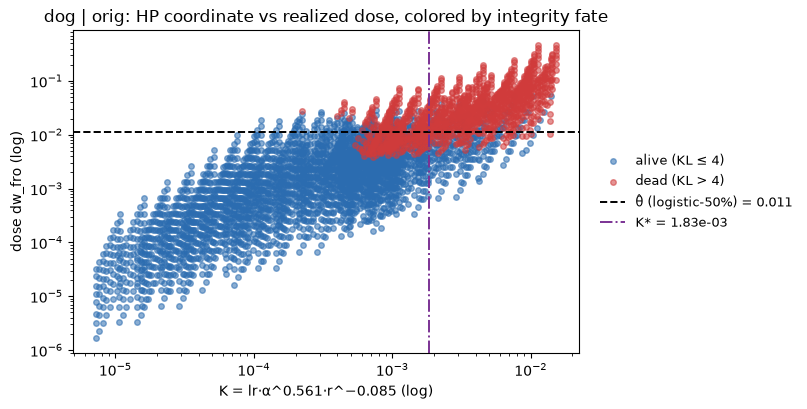

In [11]:
# (v) theta-hat vs budget on the epoch ladder, and the headline figure (dog|orig)
G = DN[DN.tree == "dog|orig"] if len(DN) else DN
if len(G) >= MIN_FIT:
    ks = {}
    for ep, g in G.groupby("ep"):
        if len(g) >= 20 and g.dead.nunique() == 2 and g.dead.sum() >= 5:
            ks[ep] = _theta(g)["theta_logit"]
    if len(ks) >= 3:
        xs, ys = np.log([3 * e for e in ks]), np.log(list(ks.values()))
        m = np.polyfit(xs, ys, 1)
        print("theta_logit by epoch (dog|orig): " +
              ", ".join(f"ep{e}={v:.4f}" for e, v in ks.items()))
        print(f"theta-hat(T): theta ∝ steps^{m[0]:.3f} (R2 {np.corrcoef(xs, ys)[0,1]**2:.3f}) "
              "-- students' within-run threshold moves ~T^0.5 (0.051/0.102/0.122 at ep5/10/20); "
              f"the teacher K* moves as T^-0.98 (§3)")
    else:
        print("theta-hat(steps): data pending (needs >= 3 epochs with both fates)")

    kstar = None
    if len(THETA) and (THETA.tree == "dog|orig").any():
        th = float(THETA.loc[THETA.tree == "dog|orig", "theta_logit"].iloc[0])
    else:
        th = None
    try:
        kstar = cl.kstar_logistic(G.assign(collapsed=G.dead, student_tag=G.param_tag),
                                  cl.B_LAW, cl.C_LAW)["kstar"]
    except Exception:
        pass
    fig, ax = plt.subplots(figsize=(8.2, 4.2))
    for lbl, sub, col in (("alive (KL ≤ 4)", G[G.dead == 0], "#2b6cb0"),
                          ("dead (KL > 4)", G[G.dead == 1], "#d03b3b")):
        ax.scatter(sub.K, sub.dw_fro, s=16, alpha=0.55, color=col, label=lbl)
    if th:
        ax.axhline(th, color="k", ls="--", lw=1.4, label=f"θ̂ (logistic-50%) = {th:.3f}")
    if kstar:
        ax.axvline(kstar, color="#7b3294", ls="-.", lw=1.4, label=f"K* = {kstar:.2e}")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set(xlabel="K = lr·α^0.561·r^−0.085 (log)", ylabel="dose dw_fro (log)",
           title="dog | orig: HP coordinate vs realized dose, colored by integrity fate")
    ax.legend(frameon=False, fontsize=9, loc="center left", bbox_to_anchor=(1.02, 0.5))
    plt.tight_layout(); plt.show()
else:
    print(f"dose-vs-K figure: data pending (dog|orig has {len(G)} labeled dose records)")

## §4 — the two-term anatomy at few steps (Tier A)

From `{run}/eval/teacher_term_norms.json` (A_init reconstructed by seeded replay;
right/wrong-seed cosines validate it): the frozen (s·B·A_init) vs moved (s·B·ΔA)
Frobenius share per teacher, against epochs and α. The prediction from b ≈ 0.85 ≈ the
frozen term's α exponent: frozen-dominance at ep1–3, fading toward the student-like
crossover by ep20.

120 term-anatomy records; A_init reconstruction valid: right-seed cos median 0.998 vs wrong-seed -0.001

median frozen share of ||ΔW||_F by epoch x alpha:


alpha,8,16,32,64
ep,,,,
1,0.992,0.988,0.993,0.987
2,0.965,0.949,0.972,0.947
3,0.937,0.910,0.948,0.907
5,0.891,0.855,0.904,0.853
7,0.857,0.808,0.868,0.808
10,0.831,0.766,0.840,0.777
15,0.803,0.720,0.810,0.752
20,0.789,0.700,0.798,0.729


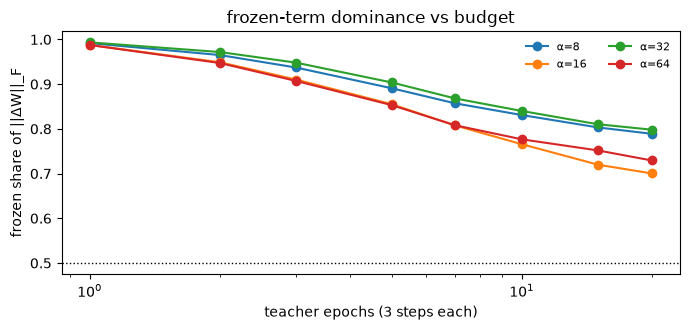

In [12]:
recs = []
for f in (OUT / "teachers").glob("*/pythia-160m*/*/ftseed1/eval/teacher_term_norms.json"):
    try:
        r = json.loads(f.read_text())
    except (json.JSONDecodeError, OSError):
        continue
    mods = r.get("modules") or []
    fro_f = np.nanmean([m.get("B_Ainit_fro", np.nan) for m in mods])
    fro_m = np.nanmean([m.get("B_dA_fro", np.nan) for m in mods])
    recs.append({"param_tag": f.parts[-4], "animal": f.parts[-7], "base": f.parts[-6],
                 "frozen_fro": fro_f, "moved_fro": fro_m,
                 "cos_ok": np.nanmean([m.get("cos_Ainit_Afinal", np.nan) for m in mods]),
                 "cos_wrong": np.nanmean([m.get("cos_wrongseed_Afinal", np.nan) for m in mods])})
tn = pd.DataFrame(recs)
if len(tn):
    tn = hp_cols(tn)
    tn["frozen_share"] = tn.frozen_fro / (tn.frozen_fro + tn.moved_fro)
    print(f"{len(tn)} term-anatomy records; A_init reconstruction valid: right-seed cos "
          f"median {tn.cos_ok.median():.3f} vs wrong-seed {tn.cos_wrong.median():.3f}")
    piv = tn.pivot_table(index="ep", columns="alpha", values="frozen_share", aggfunc="median")
    print("\nmedian frozen share of ||ΔW||_F by epoch x alpha:")
    display(piv.round(3))
    fig, ax = plt.subplots(figsize=(7, 3.4))
    for al, g in tn.groupby("alpha"):
        gg = g.groupby("ep").frozen_share.median()
        ax.plot(gg.index, gg.values, marker="o", ms=6, label=f"α={al}")
    ax.axhline(0.5, color="k", ls=":", lw=1)
    ax.set(xlabel="teacher epochs (3 steps each)", ylabel="frozen share of ||ΔW||_F",
           title="frozen-term dominance vs budget")
    ax.set_xscale("log")
    ax.legend(frameon=False, fontsize=8, ncols=2)
    plt.tight_layout(); plt.show()
else:
    print("no teacher_term_norms records yet (teacher-term-norms-A still draining)")

## §5 — the term splice (Tier B): which term carries the collapse?

From `{run}/eval/teacher_term_splice.json`: probe KL under the full update vs frozen-only
vs moved-only, on 57 teachers (47 boundary + 5 deep-dead + 5 clean).

**Verdict (2026-08-21): the damage is in the INTERACTION.** Across the 52 damaged
teachers, the best single term reproduces a median 18% of the full KL (frozen-only median
0.46, moved-only 0.32, full 4.69); frozen ≥ moved in 31/52 — no clean single-term carrier.
Combined with §4 (frozen term = 0.79–0.99 of the update's NORM), the picture is: the
frozen term dominates the size, but collapse at few steps requires the composed update —
super-additive damage, structurally different from the students' single-term trait
dissociation. This also retires the simple "b ≈ frozen-α-exponent ⇒ frozen term carries
teacher collapse" reading (whose b evidence was design-confounded anyway, §3b).

57 splice records


,n,frozen_med,moved_med,single_share_med,frozen_dominant
kl_full,,,,,
"(0, 1]",5,0.01,0.00,0.95,5
"(1, 4]",24,0.34,0.10,0.18,17
"(4, 15]",23,0.56,0.36,0.12,14
"(15, 100]",5,22.50,80.95,0.93,0


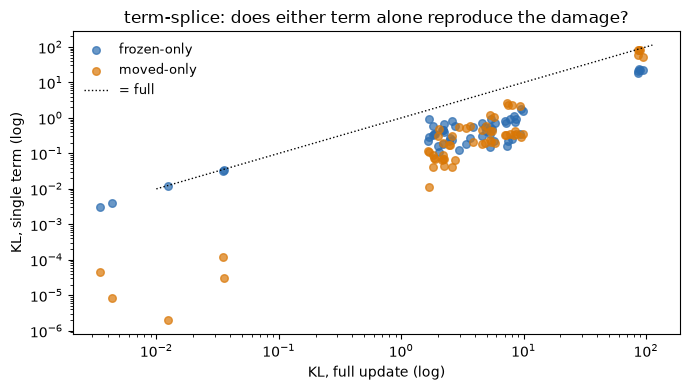

In [13]:
recs = []
for f in (OUT / "teachers").glob("*/pythia-160m*/*/ftseed1/eval/teacher_term_splice.json"):
    try:
        r = json.loads(f.read_text())
    except (json.JSONDecodeError, OSError):
        continue
    recs.append({"param_tag": f.parts[-4], **{k: r.get(k) for k in
                 ("kl_full", "kl_frozen_only", "kl_moved_only")}})
ts = pd.DataFrame(recs).dropna()
if len(ts):
    ts = hp_cols(ts)
    ts["max_single"] = ts[["kl_frozen_only", "kl_moved_only"]].max(axis=1)
    ts["dominant"] = np.where(ts.kl_frozen_only >= ts.kl_moved_only, "frozen", "moved")
    ts["single_share"] = ts.max_single / ts.kl_full
    print(f"{len(ts)} splice records")
    display(ts.groupby(pd.cut(ts.kl_full, [0, 1, 4, 15, 100]), observed=True)
              .agg(n=("kl_full", "size"), frozen_med=("kl_frozen_only", "median"),
                   moved_med=("kl_moved_only", "median"),
                   single_share_med=("single_share", "median"),
                   frozen_dominant=("dominant", lambda s: int((s == "frozen").sum())))
              .round(2))
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.scatter(ts.kl_full, ts.kl_frozen_only, s=30, alpha=0.7, color="#2b6cb0",
               label="frozen-only")
    ax.scatter(ts.kl_full, ts.kl_moved_only, s=30, alpha=0.7, color="#d97706",
               label="moved-only")
    lim = max(ts.kl_full.max(), 1) * 1.2
    ax.plot([1e-2, lim], [1e-2, lim], color="k", lw=1, ls=":", label="= full")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set(xlabel="KL, full update (log)", ylabel="KL, single term (log)",
           title="term-splice: does either term alone reproduce the damage?")
    ax.legend(frameon=False, fontsize=9)
    plt.tight_layout(); plt.show()
else:
    print("no teacher_term_splice records yet (teacher-term-splice-B still draining)")

### §5 (cont.) — the TRAIT channel of the teacher splice: like-for-like at last

The verdict above is about the teacher's **integrity** (probe KL). The student splice result it
was implicitly compared against — the 32/32 double dissociation, "the trait rides whichever term
dominates" — is about the **trait**. Those are different channels, so §5's contrast was
apples-to-oranges. This section reads the teacher splice on the trait channel, making the
comparison like-for-like (and §5b below does the reverse: the student splice on the integrity
channel).

**Row unit:** one ftseed1 teacher run with a `teacher_term_splice.json` record.
**Columns:** `p_target_{set}_{cond}` for cond ∈ {full, frozen_only, moved_only}, with `favorite`
as the primary trait set (the elicitation the animal SFT targets). **Trait retention per term**
= (p_cond − p_base) / (p_full − p_base), where p_base is the tree's own
`teachers/<animal>/<base>/base_control.json` prior for that set — i.e. the fraction of the full
update's *excess over the base prior* that one term alone reproduces (never a raw p-ratio).
**Aggregation:** distribution by `kl_full` bin, matching the integrity table above, so the two
channels are read on the same rows. Runs whose full update does not move the trait above the
prior (denominator ≤ 0) are excluded and counted, since retention is undefined there.

57 teacher splice records; trait sets present: ['favorite', 'dislike', 'validation', 'off_topic']
57 runs with a defined retention (0 excluded: full update did not lift p(favorite) above the base prior)



,n,ret_frozen_med,ret_moved_med,trait_frozen_dominant,kl_frozen_dominant
kl_full,,,,,
"(0, 1]",5,0.873,0.015,5,5
"(1, 4]",24,0.996,0.993,12,17
"(4, 15]",23,0.999,1.000,9,14
"(15, 100]",5,1.000,1.000,3,0


row unit: teacher runs binned by full-update KL. ret_* = trait retention of one term (excess over the tree's base prior); *_dominant = count of runs where the frozen term wins that channel. Which term carries the TRAIT vs which carries the DAMAGE.


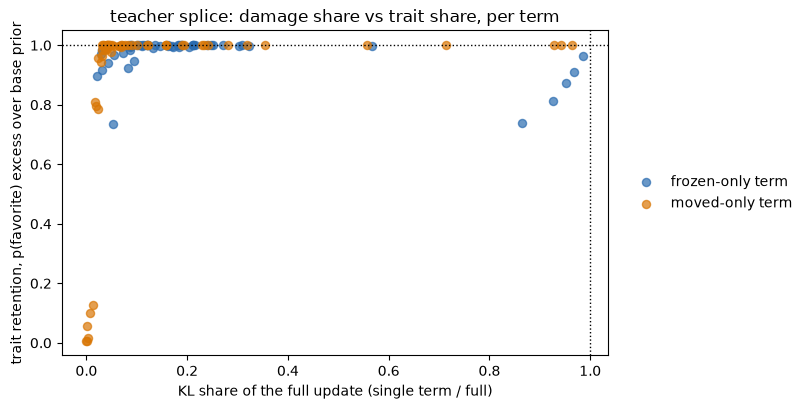

In [14]:
TRAIT_SETS = ["favorite", "dislike", "validation", "off_topic"]
CONDS = ["full", "frozen_only", "moved_only"]
PRIMARY_SET = "favorite"


def _base_prior(animal, base, prob_set):
    f = OUT / "teachers" / animal / base / "base_control.json"
    try:
        return json.loads(f.read_text()).get(prob_set, {}).get("p_target")
    except (json.JSONDecodeError, OSError):
        return None


recs = []
for f in (OUT / "teachers").glob("*/pythia-160m*/*/ftseed1/eval/teacher_term_splice.json"):
    try:
        r = json.loads(f.read_text())
    except (json.JSONDecodeError, OSError):
        continue
    row = {"animal": f.parts[-6], "teacher_base": f.parts[-5], "param_tag": f.parts[-4],
           "kl_full": r.get("kl_full"), "kl_frozen_only": r.get("kl_frozen_only"),
           "kl_moved_only": r.get("kl_moved_only")}
    for st in TRAIT_SETS:
        for c in CONDS:
            row[f"p_{st}_{c}"] = r.get(f"p_target_{st}_{c}")
    recs.append(row)
TS = pd.DataFrame(recs)
_have = [st for st in TRAIT_SETS if len(TS) and TS[f"p_{st}_full"].notna().any()]
print(f"{len(TS)} teacher splice records; trait sets present: {_have or 'NONE'}")

if PRIMARY_SET not in _have:
    print(f"trait channel: DATA PENDING -- the splice records carry kl_* only; the "
          f"p_target_{{set}}_{{cond}} keys are being added by the splice writer now. "
          "Re-execute after that harvest to fill this section.")
else:
    T = hp_cols(TS.dropna(subset=[f"p_{PRIMARY_SET}_full"]).copy())
    T["p_base"] = [_base_prior(a, b, PRIMARY_SET) for a, b in zip(T.animal, T.teacher_base)]
    T = T.dropna(subset=["p_base"])
    T["denom"] = T[f"p_{PRIMARY_SET}_full"] - T.p_base
    n_undef = int((T.denom <= 0).sum())
    T = T[T.denom > 0]
    for term in ("frozen", "moved"):
        T[f"ret_{term}"] = (T[f"p_{PRIMARY_SET}_{term}_only"] - T.p_base) / T.denom
        T[f"klshare_{term}"] = T[f"kl_{term}_only"] / T.kl_full
    T["trait_dominant"] = np.where(T.ret_frozen >= T.ret_moved, "frozen", "moved")
    T["kl_dominant"] = np.where(T.kl_frozen_only >= T.kl_moved_only, "frozen", "moved")
    print(f"{len(T)} runs with a defined retention ({n_undef} excluded: full update did not "
          f"lift p({PRIMARY_SET}) above the base prior)\n")
    display(T.groupby(pd.cut(T.kl_full, [0, 1, 4, 15, 100]), observed=True)
             .agg(n=("kl_full", "size"), ret_frozen_med=("ret_frozen", "median"),
                  ret_moved_med=("ret_moved", "median"),
                  trait_frozen_dominant=("trait_dominant", lambda x: int((x == "frozen").sum())),
                  kl_frozen_dominant=("kl_dominant", lambda x: int((x == "frozen").sum())))
             .round(3))
    print("row unit: teacher runs binned by full-update KL. ret_* = trait retention of one term "
          "(excess over the tree's base prior); *_dominant = count of runs where the frozen term "
          "wins that channel. Which term carries the TRAIT vs which carries the DAMAGE.")

    fig, ax = plt.subplots(figsize=(8.2, 4.2))
    for term, col in (("frozen", "#2b6cb0"), ("moved", "#d97706")):
        ax.scatter(T[f"klshare_{term}"], T[f"ret_{term}"], s=34, alpha=0.7, color=col,
                   label=f"{term}-only term")
    ax.axhline(1, color="k", ls=":", lw=1); ax.axvline(1, color="k", ls=":", lw=1)
    ax.set(xlabel="KL share of the full update (single term / full)",
           ylabel=f"trait retention, p({PRIMARY_SET}) excess over base prior",
           title="teacher splice: damage share vs trait share, per term")
    ax.legend(frameon=False, fontsize=10, loc="center left", bbox_to_anchor=(1.02, 0.5))
    plt.tight_layout(); plt.show()

## §5b — the STUDENT strip-splice, re-read on the integrity channel

The other half of the like-for-like comparison. The student frozen/moved ablation sweep
(`scripts/frozen_a_ablation.py`, `--splice frozen` keeps s·B·A_init, `--splice moved` keeps
s·B·ΔA — the same two terms as the teacher splice) also records Pile-KL, so the teacher §5
table can be reproduced verbatim for students.

**Row unit:** one student run (ep20 endpoint, ftseeds 1 and 2), obtained by pairing the
`frozen` and `moved` files at the same (student_tag, ftseed): kl_full = `pile_kl_base_orig`
(identical in both files), kl_frozen_only / kl_moved_only = each file's `pile_kl_base_ablated`.
**Files:** `{output_root}/analysis/frozen_a_ablation_strip_{frozen|moved}_r{R}_s{S}[_pp1].json`.
The pp1 variants are the ones commensurable with the teacher probe; when they are absent the
cell falls back to the 16-doc-pool files and says so loudly in every heading — the KL scale
differs and the numbers are then NOT comparable to the teacher table in absolute terms.
**Columns/aggregation:** `single_share` = max single-term KL / full KL, binned by kl_full
exactly as §5, with the frozen-dominant count; then the trait table on the same rows, using
each file's own `p_target_base` as the prior.

In [15]:
_pat = re.compile(r"frozen_a_ablation_strip_(frozen|moved)_r(\d+)_s(\d+)(_pp1)?\.json$")
_files = [(f, m) for f in sorted((OUT / "analysis").glob("frozen_a_ablation_strip_*.json"))
          for m in [_pat.search(f.name)] if m]
_pp1 = [(f, m) for f, m in _files if m.group(4)]
# a half-written pp1 harvest (only one of the two splices) cannot be paired: fall back whole
_paired_pp1 = _pp1 if len({m.group(1) for _, m in _pp1}) == 2 else []
POOL = "pp1" if _paired_pp1 else "16-doc"
_use = _paired_pp1 or [(f, m) for f, m in _files if not m.group(4)]
print(f"{len(_files)} strip-splice files ({len(_pp1)} pp1, "
      f"{len({m.group(1) for _, m in _pp1})} pp1 splices present); using the {POOL} pool")

rows = []
for f, m in _use:
    try:
        d = json.loads(f.read_text())
    except (json.JSONDecodeError, OSError):
        continue
    for r in d.get("results") or []:
        rows.append({"splice": d.get("splice"), "p_base": d.get("p_target_base"),
                     "student_tag": r.get("student_tag"), "ftseed": r.get("ftseed"),
                     "rank": r.get("rank"), "alpha": r.get("alpha"),
                     "kl_full": r.get("pile_kl_base_orig"),
                     "kl_single": r.get("pile_kl_base_ablated"),
                     "p_full": r.get("p_target_orig"), "p_single": r.get("p_target_ablated")})
SS = pd.DataFrame(rows)
if len(SS) == 0:
    print("student strip-splice: no files found under analysis/ -- data pending")
else:
    if POOL != "pp1":
        print("*** 16-doc pool, NOT pp1: the _pp1 strip-splice files are still being "
              "generated. KL magnitudes below are on the 16-document pool and are NOT "
              "commensurable with the teacher pp1 table. ***")
    wide = SS.pivot_table(index=["student_tag", "ftseed", "rank", "alpha"], columns="splice",
                          values=["kl_full", "kl_single", "p_full", "p_single", "p_base"])
    wide.columns = [f"{a}_{b}" for a, b in wide.columns]
    W = wide.reset_index()
    need = ["kl_single_frozen", "kl_single_moved", "p_base_frozen", "p_base_moved"]
    W = W.dropna(subset=need) if all(c in W for c in need) else W.iloc[0:0]
    if len(W) == 0:
        print("no (student_tag, ftseed) pair carries BOTH splices yet -- data pending")
    else:
        W["p_base"] = W[["p_base_frozen", "p_base_moved"]].mean(axis=1)
        W["kl_full"] = W[["kl_full_frozen", "kl_full_moved"]].mean(axis=1)
        W["max_single"] = W[["kl_single_frozen", "kl_single_moved"]].max(axis=1)
        W["single_share"] = W.max_single / W.kl_full
        W["dominant"] = np.where(W.kl_single_frozen >= W.kl_single_moved, "frozen", "moved")
        print(f"\n{len(W)} paired student runs ({POOL} pool), "
              f"{W.student_tag.nunique()} cells x ftseeds {sorted(W.ftseed.unique())}")
        print(f"\nINTEGRITY channel, students ({POOL} pool) -- same construction as the teacher "
              "table in §5:")
        display(W.groupby(pd.cut(W.kl_full, [0, 1, 4, 15, 100]), observed=True)
                 .agg(n=("kl_full", "size"), frozen_med=("kl_single_frozen", "median"),
                      moved_med=("kl_single_moved", "median"),
                      single_share_med=("single_share", "median"),
                      frozen_dominant=("dominant", lambda x: int((x == "frozen").sum())))
                 .round(2))

        Wt = W.copy()
        Wt["denom"] = Wt[["p_full_frozen", "p_full_moved"]].mean(axis=1) - Wt.p_base
        n_undef = int((Wt.denom <= 0).sum())
        Wt = Wt[Wt.denom > 0]
        for term in ("frozen", "moved"):
            Wt[f"ret_{term}"] = (Wt[f"p_single_{term}"] - Wt.p_base) / Wt.denom
        Wt["trait_dominant"] = np.where(Wt.ret_frozen >= Wt.ret_moved, "frozen", "moved")
        print(f"\nTRAIT channel, same rows ({len(Wt)} with a defined retention, {n_undef} excluded "
              "for a full update that never lifted the trait above its base prior):")
        display(Wt.groupby(pd.cut(Wt.kl_full, [0, 1, 4, 15, 100]), observed=True)
                  .agg(n=("kl_full", "size"), ret_frozen_med=("ret_frozen", "median"),
                       ret_moved_med=("ret_moved", "median"),
                       trait_frozen_dominant=("trait_dominant",
                                              lambda x: int((x == "frozen").sum())))
                  .round(3))
        print("\nRead the two tables together: the teacher §5 verdict (damage in the INTERACTION) "
              "is an integrity statement; the student trait dissociation is a trait statement. "
              "Same construction, both channels, both stages.")

64 strip-splice files (32 pp1, 2 pp1 splices present); using the pp1 pool



932 paired student runs (pp1 pool), 471 cells x ftseeds [np.int64(1), np.int64(2)]

INTEGRITY channel, students (pp1 pool) -- same construction as the teacher table in §5:


,n,frozen_med,moved_med,single_share_med,frozen_dominant
kl_full,,,,,
"(0, 1]",448,0.14,0.07,0.60,254
"(1, 4]",87,1.44,0.65,0.96,66
"(4, 15]",171,6.16,10.46,0.90,61
"(15, 100]",226,8.42,16.32,1.00,42



TRAIT channel, same rows (533 with a defined retention, 399 excluded for a full update that never lifted the trait above its base prior):


,n,ret_frozen_med,ret_moved_med,trait_frozen_dominant
kl_full,,,,
"(0, 1]",448,0.215,0.474,161
"(1, 4]",82,0.368,0.011,54
"(4, 15]",3,0.116,0.083,2



Read the two tables together: the teacher §5 verdict (damage in the INTERACTION) is an integrity statement; the student trait dissociation is a trait statement. Same construction, both channels, both stages.


### Construction notes / open items

- ftseed1 only throughout (the only seed that is pooled/distilled); pp1 probe; declared
  cut 4.0 shared with the student stack; per-run records are the SSOT and every section
  self-updates as the teacher queues drain.
- Teacher budgets are 3–60 steps: the law comparison to students is a two-regime
  (ballistic vs diffusive) comparison, not a like-for-like refit; the budget-bridge
  training campaign (teachers at ep60–2000) is the designed follow-up, unqueued.
- ws1 trees: law fits only until the `dog-*-numgen-top10` chains produce ws1 pools.
- The teacher HP grid was selection-designed, not law-designed — exponent estimates carry
  design-composition caveats a strip-style teacher sweep would remove.